In [29]:
import numpy as np, pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
import seaborn as sns, matplotlib.pyplot as plt
from sklearn.utils import resample

In [30]:
windows_qc = pd.read_csv("outputs/windows_requested_features2.csv")

In [1]:
FEATS = [
    "fix_count","fix_mean_dur","fix_aoi_ratio",
    "gaze_x_dispersion","gaze_y_dispersion",
    "pupil_mean","pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_count","blink_mean_dur",
    "valid_gaze_ratio",
]

df = windows_qc.copy()
df["label"] = df["label"].astype(str).str.upper().str.strip()
df["type"]  = df["type"].astype(str).str.upper().str.strip()

Xraw = df[FEATS].copy()
y_lab = df["label"].values
y_typ = df["type"].values

# ---------- 1) Basic sanity: drop near-constant features & strong duplicates ----------
# (a) variance threshold (after naive fill to avoid nan variance)
tmp = Xraw.fillna(Xraw.median(numeric_only=True))
var = tmp.var(axis=0)
keep_var = var[var > 1e-6].index.tolist()
Xvar = Xraw[keep_var]

# (b) drop one of any pair with |r|>0.95 (simple greedy)
corr = Xvar.fillna(Xvar.median()).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_cols = [c for c in upper.columns if any(upper[c] > 0.95)]
Xsel = Xvar.drop(columns=drop_cols) if drop_cols else Xvar

print("Kept features:", list(Xsel.columns))


pipe_imputer = SimpleImputer(strategy="median")
pipe_scaler  = StandardScaler()

X_imp = pipe_imputer.fit_transform(Xsel)
X     = pipe_scaler.fit_transform(X_imp)

# ---------- 3) PCA ----------
pca = PCA(n_components=2, random_state=0)
PC   = pca.fit_transform(X)
print("PCA explained variance:", pca.explained_variance_ratio_)

df_pca = df.copy()
df_pca["PC1"] = PC[:,0]
df_pca["PC2"] = PC[:,1]

# Plot: colored by ON/OFF
sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=0),
                x="PC1", y="PC2", hue="label", alpha=0.5)
plt.title("PCA (2D) colored by ON/OFF")
plt.axhline(0, lw=0.5, ls="--"); plt.axvline(0, lw=0.5, ls="--")
plt.tight_layout(); plt.show()


# Plot: colored by animation type
sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=0),
                x="PC1", y="PC2", hue="type", alpha=0.5, legend=False)
plt.title("PCA (2D) colored by animation type")
plt.axhline(0, lw=0.5, ls="--"); plt.axvline(0, lw=0.5, ls="--")
plt.tight_layout(); plt.show()




# ---------- 4) KMeans: k=2 (compare to ON/OFF) ----------
km2 = KMeans(n_clusters=2, n_init="auto", random_state=0)
lab2 = km2.fit_predict(X)

# Map clusters → ON/OFF by majority vote
def majority_map(pred, truth):
    dfm = pd.DataFrame({"c":pred, "t":truth})
    mapping = {}
    for c, grp in dfm.groupby("c"):
        top = grp["t"].value_counts().idxmax()
        mapping[c] = top
    return np.vectorize(mapping.get)(pred), mapping

lab2_mapped, mapping2 = majority_map(lab2, y_lab)
acc2 = (lab2_mapped == y_lab).mean()
sil2 = silhouette_score(X, lab2) if len(np.unique(lab2)) > 1 else np.nan
print(f"KMeans k=2 → align with ON/OFF: acc={acc2:.3f}, silhouette={sil2:.3f}, map={mapping2}")

# Visualize clusters on PCA
df_pca["km2"] = lab2
sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=1),
                x="PC1", y="PC2", hue="km2", alpha=0.5)
plt.title("KMeans (k=2) in PCA space")
plt.tight_layout(); plt.show()

# ---------- 5) KMeans: k=3 (roughly compare to FADE/SCROLL/BOUNCE) ----------
km3 = KMeans(n_clusters=3, n_init="auto", random_state=0)
lab3 = km3.fit_predict(X)
sil3 = silhouette_score(X, lab3) if len(np.unique(lab3)) > 1 else np.nan

# Purity by true type
purity = (
    pd.DataFrame({"c":lab3, "t":y_typ})
    .groupby("c")["t"]
    .apply(lambda s: s.value_counts(normalize=True).head(1).iloc[0])
    .mean()
)
print(f"KMeans k=3 → silhouette={sil3:.3f}, mean cluster purity vs type={purity:.3f}")

df_pca["km3"] = lab3
sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=2),
                x="PC1", y="PC2", hue="km3", alpha=0.5)
plt.title("KMeans (k=3) in PCA space")
plt.tight_layout(); plt.show()

# ---------- 6) DBSCAN (auto eps heuristic) ----------
# Heuristic: use median pairwise distance of a small sample as eps baseline
sample_idx = np.random.default_rng(0).choice(len(X), size=min(5000, len(X)), replace=False)
Xs = X[sample_idx]
# fast approx: distance to 5th nearest neighbor
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=5).fit(Xs)
dists, _ = nn.kneighbors(Xs)
eps = np.median(dists[:, -1])  # median 5-NN distance
db = DBSCAN(eps=float(eps), min_samples=20).fit(X)
labels_db = db.labels_

n_clusters = (labels_db >= 0).sum() and len(np.unique(labels_db[labels_db >= 0])) or 0
sil_db = silhouette_score(X[labels_db>=0], labels_db[labels_db>=0]) if n_clusters>1 else np.nan
print(f"DBSCAN → clusters={n_clusters}, noise={(labels_db<0).mean():.2%}, silhouette={sil_db if np.isfinite(sil_db) else np.nan}")

df_pca["db"] = labels_db
sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=3),
                x="PC1", y="PC2", hue="db", palette="tab10", alpha=0.5)
plt.title("DBSCAN in PCA space (−1 = noise)")
plt.tight_layout(); plt.show()

# ---------- 7) Simple heatmap: cluster x ON/OFF composition ----------
comp = pd.crosstab(df_pca["km2"], df_pca["label"], normalize='index')
sns.heatmap(comp, annot=True, fmt=".2f", cmap="Blues")
plt.title("KMeans k=2 clusters vs ON/OFF (row-normalized)")
plt.ylabel("Cluster"); plt.xlabel("Label")
plt.tight_layout(); plt.show()

NameError: name 'windows_qc' is not defined

# pca 2

Kept features: ['fix_efficiency', 'fix_aoi_ratio', 'gaze_dispersion_total', 'pupil_mean', 'pupil_var', 'saccade_mean_mag', 'saccade_dir_var', 'blink_rate', 'valid_gaze_ratio']


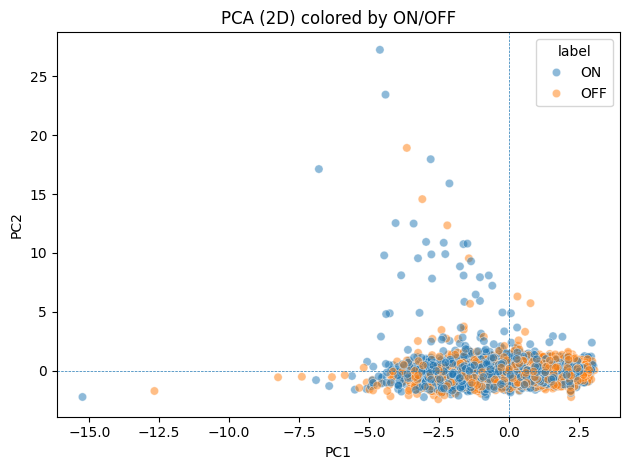

Balanced counts:
 label
OFF    2144
ON     2144
Name: count, dtype: int64
label       OFF        ON
km2                      
0      0.446682  0.553318
1      0.534615  0.465385


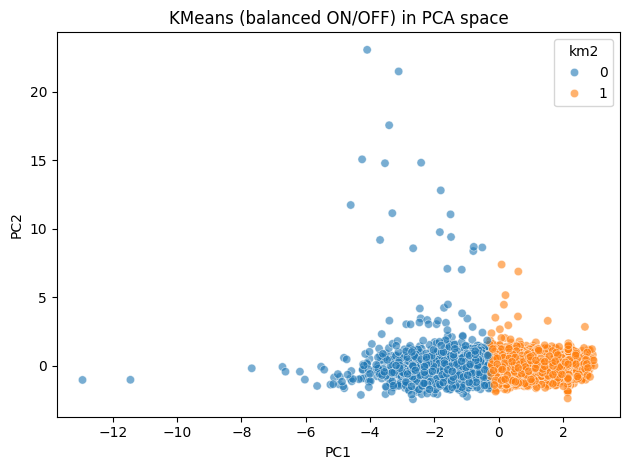

In [40]:
# -------- feature list you designed --------
FEATS = [
    "fix_efficiency", "fix_aoi_ratio",
    "gaze_dispersion_total",
    "pupil_mean", "pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_rate",
    "valid_gaze_ratio",
]

df = windows_qc.copy()
df["label"] = df["label"].astype(str).str.upper().str.strip()
df["type"]  = df["type"].astype(str).str.upper().str.strip()

Xraw  = df[FEATS].copy()
y_lab = df["label"].values
y_typ = df["type"].values

# ---------- 1) Drop near-constant and highly correlated features ----------
tmp     = Xraw.fillna(Xraw.median(numeric_only=True))
var     = tmp.var(axis=0)
keep_var_names = var[var > 1e-6].index.tolist()
Xvar    = Xraw[keep_var_names]

corr   = Xvar.fillna(Xvar.median()).corr().abs()
upper  = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_cols = [c for c in upper.columns if any(upper[c] > 0.95)]
Xsel   = Xvar.drop(columns=drop_cols) if drop_cols else Xvar
feats_kept = list(Xsel.columns)         # <- remember these for later
print("Kept features:", feats_kept)

# ---------- 2) Impute + scale ----------
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.utils import resample
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

imp = SimpleImputer(strategy="median")
scl = StandardScaler()
X   = scl.fit_transform(imp.fit_transform(Xsel))

# ---------- 3) PCA (for visualization only) ----------
pca = PCA(n_components=2, random_state=0)
PC  = pca.fit_transform(X)
df_pca = df.copy()
df_pca["PC1"] = PC[:,0]
df_pca["PC2"] = PC[:,1]

sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=0),
                x="PC1", y="PC2", hue="label", alpha=0.5)
plt.title("PCA (2D) colored by ON/OFF")
plt.axhline(0, lw=0.5, ls="--"); plt.axvline(0, lw=0.5, ls="--")
plt.tight_layout(); plt.show()

# ---------- 4) KMeans (k=2) on FULL data ----------
# km2 = KMeans(n_clusters=2, n_init="auto", random_state=0)
# lab2 = km2.fit_predict(X)

# def majority_map(pred, truth):
#     m = {}
#     for c, grp in pd.DataFrame({"c":pred,"t":truth}).groupby("c"):
#         m[c] = grp["t"].value_counts().idxmax()
#     return np.vectorize(m.get)(pred), m

# lab2_mapped, mapping2 = majority_map(lab2, y_lab)
# acc2 = (lab2_mapped == y_lab).mean()
# sil2 = silhouette_score(X, lab2) if len(np.unique(lab2)) > 1 else np.nan
# print(f"KMeans k=2 (full) → acc={acc2:.3f}, silhouette={sil2:.3f}, map={mapping2}")

# df_pca["km2"] = lab2
# sns.scatterplot(data=df_pca.sample(min(8000, len(df_pca)), random_state=1),
#                 x="PC1", y="PC2", hue="km2", alpha=0.5)
# plt.title("KMeans (k=2) in PCA space")
# plt.tight_layout(); plt.show()

# ================= BALANCED ON/OFF =================
# pick the same row indices to balance, then go back to the ORIGINAL df to build features
on_idx  = df.index[df["label"]=="ON"]
off_idx = df.index[df["label"]=="OFF"]
n = min(len(on_idx), len(off_idx))
on_down_idx  = resample(on_idx, replace=False, n_samples=n, random_state=0)
off_down_idx = resample(off_idx, replace=False, n_samples=n, random_state=0)
keep_idx = np.concatenate([on_down_idx, off_down_idx])
df_balanced = df.loc[keep_idx].sample(frac=1, random_state=0)  # shuffle
print("Balanced counts:\n", df_balanced["label"].value_counts())

# build feature matrix AGAIN using the kept feature names
Xb = df_balanced[feats_kept].copy()
Xb = scl.fit_transform(imp.fit_transform(Xb))   # fit scaler/imputer anew on the balanced set

# PCA for balanced viz
pca_b = PCA(n_components=2, random_state=0)
PCb   = pca_b.fit_transform(Xb)
df_balanced["PC1"] = PCb[:,0]
df_balanced["PC2"] = PCb[:,1]

# KMeans on balanced (in PCA space for plotting)
km2_b = KMeans(n_clusters=2, n_init="auto", random_state=0)
lab2b = km2_b.fit_predict(PCb)
df_balanced["km2"] = lab2b

print(pd.crosstab(df_balanced["km2"], df_balanced["label"], normalize="index"))

sns.scatterplot(data=df_balanced, x="PC1", y="PC2", hue="km2", alpha=0.6)
plt.title("KMeans (balanced ON/OFF) in PCA space")
plt.tight_layout(); plt.show()

what are the features that matter the most?

In [2]:
# ---- Config ----
FEATS = [
    "fix_efficiency", "fix_aoi_ratio",
    "gaze_dispersion_total",
    "pupil_mean", "pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_rate",
    "valid_gaze_ratio",
]

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def pca_loadings_by_type(df, feats=FEATS, types=None, topk=10, random_state=0):
    """
    For each animation type, run PCA (2 PCs) on the given features and
    report/plot the top absolute loadings for PC1 and PC2.
    """
    if types is None:
        types = (
            df["type"].astype(str).str.upper().str.strip()
              .value_counts().index.tolist()
        )

    for t in types:
        sub = df[df["type"].astype(str).str.upper().str.strip() == t].copy()
        if sub.empty:
            print(f"\n[{t}] — no rows, skipping.")
            continue

        # Keep only rows with at least one finite feature value
        Xraw = sub[feats].copy()
        if Xraw.dropna(how="all").empty:
            print(f"\n[{t}] — all-NaN features, skipping.")
            continue

        # Impute + scale
        imp = SimpleImputer(strategy="median")
        scl = StandardScaler()
        X_imp = imp.fit_transform(Xraw)
        X     = scl.fit_transform(X_imp)

        # Fit PCA
        pca = PCA(n_components=2, random_state=random_state)
        PC  = pca.fit_transform(X)
        evr = pca.explained_variance_ratio_

        print(f"\n=== {t} ===  (n={len(sub)})  EVR: PC1={evr[0]:.2f}, PC2={evr[1]:.2f}")

        # Build loadings table
        loadings = pd.DataFrame(
            pca.components_.T,
            columns=[f"PC{i+1}" for i in range(pca.n_components_)],
            index=feats
        )

        # Show & plot top features per PC
        for pc in ["PC1", "PC2"]:
            top = loadings[pc].abs().sort_values(ascending=False).head(topk)
            print(f"\nTop features driving {pc} ({t}):")
            print(top)

            plt.figure(figsize=(8,4))
            sns.barplot(x=top.values, y=top.index, palette="viridis")
            plt.title(f"{t}: Top {topk} features for {pc}  (|loading|)")
            plt.xlabel("Absolute loading")
            plt.tight_layout()
            plt.show()

# ---- Run it ----
# assumes you have windows_qc with the cleaned features + 'type'
pca_loadings_by_type(windows_qc, feats=FEATS, types=["FADE","SCROLL","BOUNCE","UNKNOWN"], topk=10)

NameError: name 'windows_qc' is not defined

lets check how features are correlated

In [ ]:
# Select only your feature columns
FEATS = [
    "fix_count","fix_mean_dur","fix_aoi_ratio",
    "gaze_x_dispersion","gaze_y_dispersion",
    "pupil_mean","pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_count","blink_mean_dur",
    "valid_gaze_ratio",
]

# Compute correlations
corr = df[FEATS].corr()

# Plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap of features", fontsize=14)
plt.tight_layout()
plt.show()